In [11]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
path = kagglehub.dataset_download("atulyakumar98/pothole-detection-dataset")

print("Path to dataset files:", path)

/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/1.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/10.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/100.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/101.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/102.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/103.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/104.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/105.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/106.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/107.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/108.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal/109.jpg
/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/norm

In [1]:
import os

dataset_path = "/kaggle/input"

for dirname, subdirs, filenames in os.walk(dataset_path):
    print(f"Folder: {dirname}")
    print(f"Subfolders: {subdirs}")
    print(f"Files: {len(filenames)}")
    print("-" * 50)

Folder: /kaggle/input
Subfolders: ['datasets']
Files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets
Subfolders: ['atulyakumar98']
Files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets/atulyakumar98
Subfolders: ['pothole-detection-dataset']
Files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets/atulyakumar98/pothole-detection-dataset
Subfolders: ['normal', 'potholes']
Files: 0
--------------------------------------------------
Folder: /kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/normal
Subfolders: []
Files: 352
--------------------------------------------------
Folder: /kaggle/input/datasets/atulyakumar98/pothole-detection-dataset/potholes
Subfolders: []
Files: 329
--------------------------------------------------


In [2]:
import os
from collections import Counter

dataset_path = "/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset"

for folder in ["normal", "potholes"]:

    folder_path = os.path.join(dataset_path, folder)

    files = os.listdir(folder_path)

    extensions = Counter(
        os.path.splitext(file)[1].lower()
        for file in files
    )

    print(f"\nClass: {folder}")
    print("Total Images:", len(files))
    print("Image Formats:", extensions)


Class: normal
Total Images: 352
Image Formats: Counter({'.jpg': 352})

Class: potholes
Total Images: 329
Image Formats: Counter({'.jpg': 329})


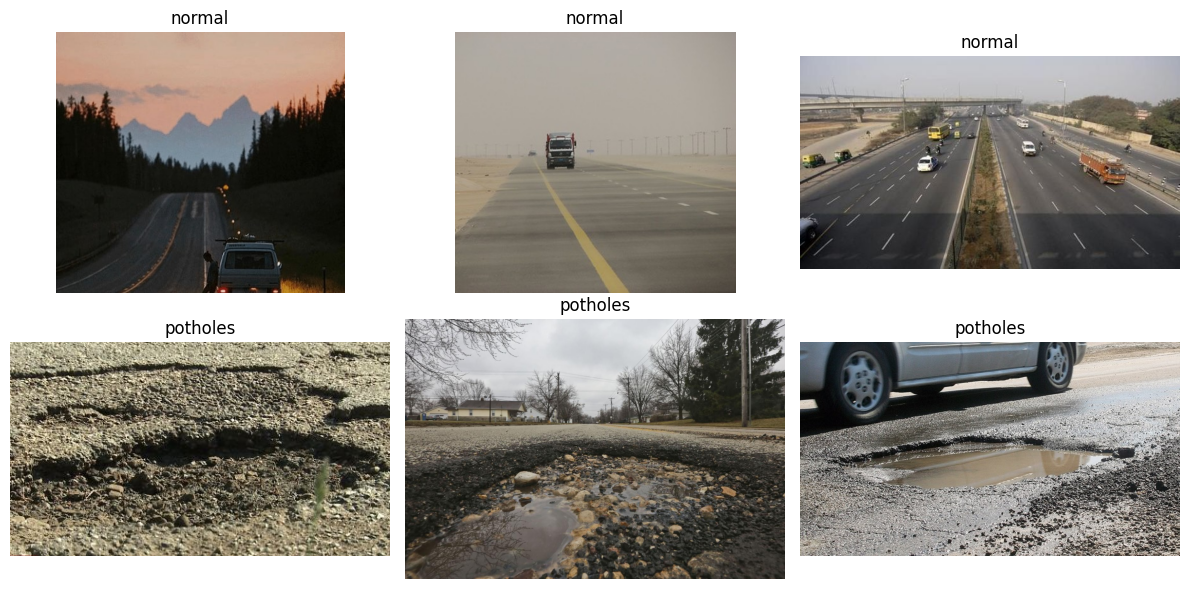

In [3]:
import os
import matplotlib.pyplot as plt
from PIL import Image
import random

dataset_path = "/kaggle/input/datasets/atulyakumar98/pothole-detection-dataset"

classes = ["normal", "potholes"]

plt.figure(figsize=(12, 6))

for i, category in enumerate(classes):
    folder = os.path.join(dataset_path, category)

    images = os.listdir(folder)
    samples = random.sample(images, 3)

    for j, image_name in enumerate(samples):
        image_path = os.path.join(folder, image_name)

        img = Image.open(image_path)

        plt.subplot(2, 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(category)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
def displayImage(img_type):
    folder = os.path.join(dataset_path, img_type)
    imgs = os.listdir(folder)
    samples = random.sample(imgs, 3)

    for image_name in samples:
        image_path = os.path.join(folder, image_name)
        img = Image.open(image_path)

        plt.imshow(img)
        plt.title(f"{img_type} road")
        plt.axis('off')
        plt.show()

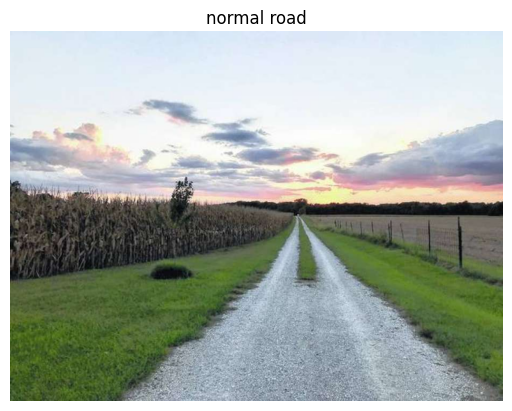

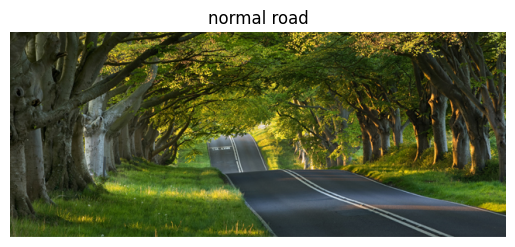

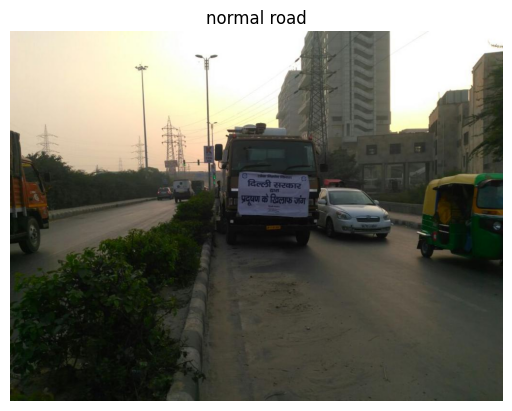

In [13]:
## display normal roads
displayImage("normal")

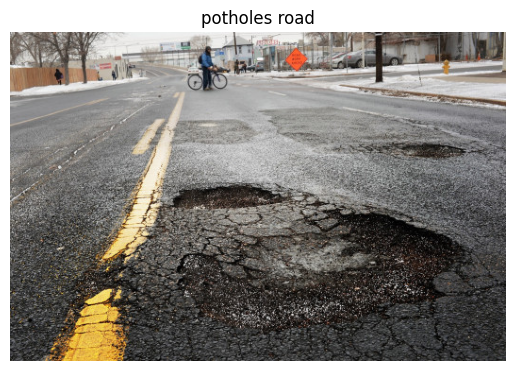

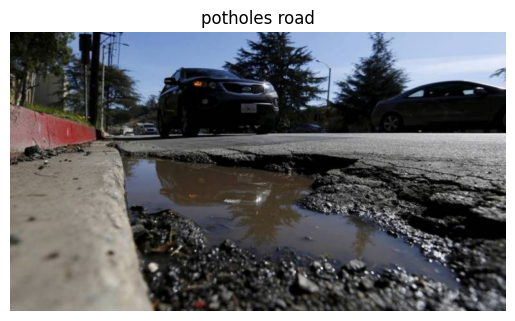

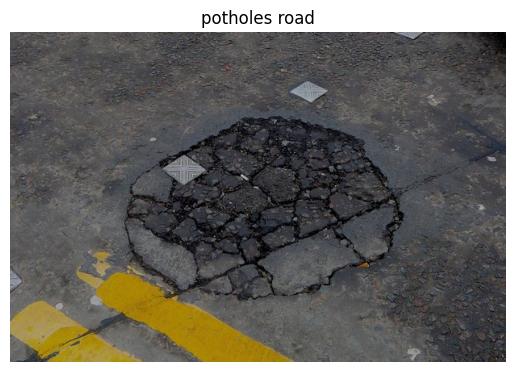

In [14]:
## display pothole roads
displayImage("potholes")

In [15]:
def checkImageProperties(img_type):
    folder = os.path.join(dataset_path, img_type)
    images = os.listdir(folder)

    image_path = os.path.join(folder, images[0])

    img = Image.open(image_path)
    print("Image Format:", img.format)
    print("Image Size:", img.size)
    print("Image Mode:", img.mode)

In [16]:
checkImageProperties('potholes')

Image Format: JPEG
Image Size: (980, 654)
Image Mode: RGB


In [17]:
def resizeImg():
    X = []
    y = []
    classes = ['normal', 'potholes']
    for label, category in enumerate(classes):
        folder = os.path.join(dataset_path, category)
        files = os.listdir(folder)
        # Iterate on every image and resize.
        for image_name in files:
            image_path = os.path.join(folder, image_name)
            img = Image.open(image_path).convert("RGB")   ## open an image and convert it into RGB
            img = img.resize((128, 128))
            # store values in numpy array
            img_array = np.array(img)
            X.append(img_array)
            y.append(label)

    X = np.array(X)
    y = np.array(y)
    return X, y

In [20]:
X, y = resizeImg()

In [21]:
print("Images Shape:", X.shape)
print("Labels Shape:", y.shape)
print("Total Images:", len(X))

Images Shape: (681, 128, 128, 3)
Labels Shape: (681,)
Total Images: 681


In [22]:
X[0][0][0]

array([209, 226, 242], dtype=uint8)

In [23]:
X = X.astype("float32")/255.0

In [24]:
print("Minimum Pixel Value:", X.min())
print("Maximum Pixel Value:", X.max())
print("Data Type:", X.dtype)

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Data Type: float32


In [25]:
from sklearn.model_selection import train_test_split
# Split data into Training and Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,y,
    test_size=0.30,
    random_state=42, 
    stratify=y
)

In [26]:
# Split data into Validation and Testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [27]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (476, 128, 128, 3)
Validation: (102, 128, 128, 3)
Testing: (103, 128, 128, 3)


In [28]:
import tensorflow as tf 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [29]:
model = Sequential([
    
    Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3)), 
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3,3), activation='relu', input_shape=(128, 128, 3)), 
    MaxPooling2D((2, 2)),
    
    Conv2D(128, (3,3), activation='relu', input_shape=(128, 128, 3)), 
    MaxPooling2D((2, 2)),

    # Classification Block
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
    
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [30]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [31]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

In [34]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop]
)

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 524ms/step - accuracy: 0.5462 - loss: 0.7801 - val_accuracy: 0.7451 - val_loss: 0.6307
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7857 - loss: 0.5061 - val_accuracy: 0.8137 - val_loss: 0.4547
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8235 - loss: 0.4159 - val_accuracy: 0.8137 - val_loss: 0.4081
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8466 - loss: 0.3434 - val_accuracy: 0.8627 - val_loss: 0.3855
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8866 - loss: 0.3014 - val_accuracy: 0.8137 - val_loss: 0.3727
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8908 - loss: 0.2545 - val_accuracy: 0.8333 - val_loss: 0.3761
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9097 - loss: 0.2383 - val_accuracy: 0.7843 - val_loss: 0.5148
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9013 - loss: 0.2254 - val_accuracy: 0.8529 -

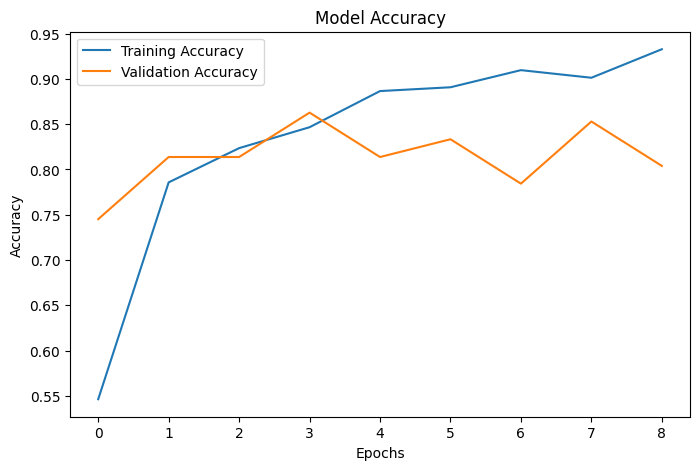

In [35]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

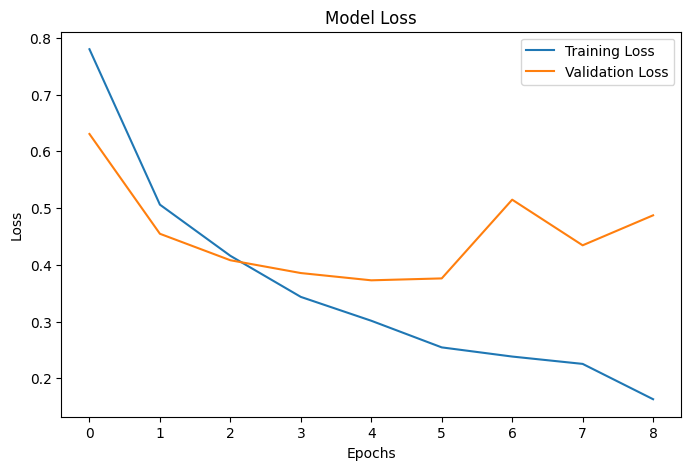

In [36]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [37]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 327ms/step - accuracy: 0.9029 - loss: 0.2441
Test Loss: 0.2441057711839676
Test Accuracy: 0.9029126167297363


In [40]:
y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)
# y_pred

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


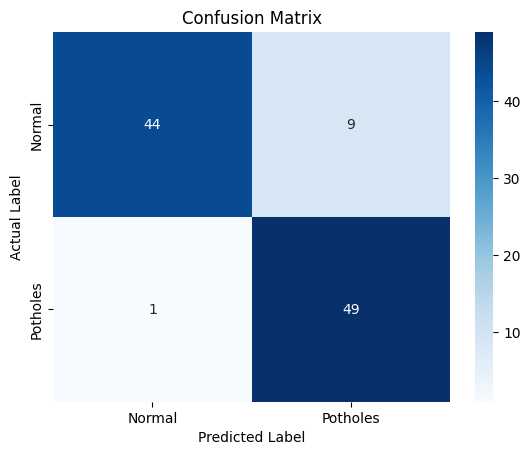

In [41]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Potholes'],
    yticklabels=['Normal', 'Potholes']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [42]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Normal', 'Potholes']
))

              precision    recall  f1-score   support

      Normal       0.98      0.83      0.90        53
    Potholes       0.84      0.98      0.91        50

    accuracy                           0.90       103
   macro avg       0.91      0.91      0.90       103
weighted avg       0.91      0.90      0.90       103



In [43]:
model.save("pothole_detection_cnn.keras")

In [44]:
text_photo_path = "/kaggle/input/datasets/preetvishwakarma99/pothole/pothole.jpg"

In [49]:
test_img = Image.open(text_photo_path)

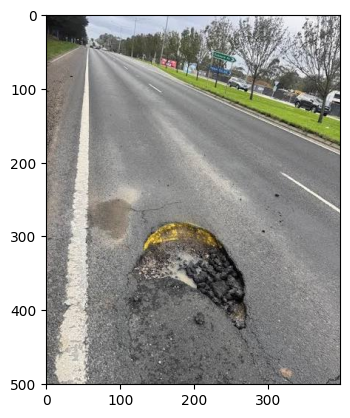

In [50]:
plt.imshow(test_img)

In [51]:
    print("Image Format:", test_img.format)
    print("Image Size:", test_img.size)
    print("Image Mode:", test_img.mode)

Image Format: JPEG
Image Size: (399, 501)
Image Mode: RGB


In [69]:
def predictions(img):
    img = img.convert("RGB").resize((128, 128))
    img = np.array(img)
    img = img.astype("float32")/255.0
    img = np.expand_dims(normalized_img, axis=0)
    result = model.predict(img_array)

    if result < 0.5:
        print("Normal")
    else:
        print("Pathole")

In [70]:
predictions(test_img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Pathole


In [71]:
import sys
import tensorflow as tf
import numpy as np
import sklearn
import PIL
import matplotlib

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Pillow:", PIL.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
NumPy: 2.1.3
Scikit-learn: 1.6.1
Pillow: 13.0.0
Matplotlib: 3.10.0
